# Analisis Pemanfaatan Generative AI dalam Pembelajaran Mahasiswa


## Persiapan

In [2]:
import itertools, warnings
from pathlib import Path
import numpy as np
import pandas as pd
from scipy.stats import spearmanr, kendalltau, mannwhitneyu
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display
warnings.filterwarnings("ignore", message="findfont")

OUT = Path("hasil"); OUT.mkdir(exist_ok=True)
SEED, B = 2026, 5000          # B = jumlah resampel bootstrap
rng = np.random.default_rng(SEED)
plt.rcParams.update({"font.family": "serif",
                     "font.serif": ["Times New Roman", "Liberation Serif", "DejaVu Serif"],
                     "font.size": 9, "savefig.dpi": 300, "savefig.bbox": "tight"})
NAMA_FILE = None              # isi manual jika ada lebih dari satu file .xlsx"

## Unggah file


In [3]:
try:
    from google.colab import files
    files.upload()
except ImportError:
    print("Bukan Google Colab: file Excel dibaca dari folder kerja.")

if NAMA_FILE is None:
    kandidat = sorted(list(Path(".").glob("*.xlsx")) + list(Path("data").glob("*.xlsx")))
    if len(kandidat) == 0:
        raise FileNotFoundError("Tidak ada file .xlsx. Unggah file jawaban Google Forms terlebih dahulu.")
    if len(kandidat) > 1:
        raise ValueError("Ada lebih dari satu file .xlsx: " + ", ".join(k.name for k in kandidat)
                         + ". Isi variabel NAMA_FILE di sel Persiapan.")
    NAMA_FILE = str(kandidat[0])
print("Membaca file:", NAMA_FILE)

Saving Data Survei AI (Lengkap).xlsx to Data Survei AI (Lengkap).xlsx
Membaca file: Data Survei AI (Lengkap).xlsx


## 1. Impor dan seleksi responden


In [4]:
raw = pd.read_excel(NAMA_FILE)
c = list(raw.columns)
n_masuk = len(raw)
lolos = (raw[c[1]].astype(str).str.strip() == "Iya") & (raw[c[2]].astype(str).str.strip() == "Iya")
raw = raw[lolos].copy()
n_duplikat = int(raw.duplicated(subset=c[1:]).sum())
raw = raw.drop_duplicates(subset=c[1:]).sort_values(c[0]).reset_index(drop=True)
print(f"Masuk: {n_masuk} | lolos penyaring: {int(lolos.sum())} | duplikat: {n_duplikat} | dianalisis: {len(raw)}")

Masuk: 39 | lolos penyaring: 39 | duplikat: 0 | dianalisis: 39


## 2. Anonimisasi
Timestamp diganti nomor urut respons (masih bisa dipakai untuk membandingkan responden awal vs akhir). Formulir tidak memuat nama/email.

In [5]:
df = pd.DataFrame({"urutan": np.arange(1, len(raw) + 1)})

## 3. Encoding

In [6]:
df["frekuensi"] = raw[c[4]].values
df["durasi"] = raw[c[5]].values
KODE = ["PU1","PU2","PU3","PU4","PEOU1","PEOU2","PEOU3","PEOU4",
        "AIL1","AIL2","AIL3","AIL4","AIL5","AIL6","RAU1","RAU2","RAU3","RAU4"]
for k, col in zip(KODE, c[9:27]):
    df[k] = pd.to_numeric(raw[col], errors="coerce").values
PU, PEOU, AIL, RAU = KODE[0:4], KODE[4:8], KODE[8:14], KODE[14:18]

TT = 6
df["AIL_tidak_tahu"] = (df[AIL] == TT).sum(axis=1)
tt_per_butir = (df[AIL] == TT).sum()
df[AIL] = df[AIL].where(df[AIL] != TT)

OPSI = {
    "app": (c[3], ["ChatGPT", "Claude", "Gemini", "Deepseek", "Perplexity", "Copilot", "Meta AI"]),
    "tujuan": (c[6], ["Memahami materi", "Coding", "Mencari ide", "Membuat rangkuman", "Menyusun laporan",
                      "Menyelesaikan soal", "Mencari referensi", "Menerjemahkan bahasa", "Membuat gambar"]),
    "aktivitas": (c[7], ["Tugas individu", "Tugas kelompok", "Belajar mandiri", "Persiapan ujian",
                         "Praktikum", "Penelitian"]),
}
for pre, (col, opts) in OPSI.items():
    teks = raw[col].fillna("").astype(str).values
    for o in opts:
        df[f"{pre}:{o}"] = [int(o.lower() in t.lower()) for t in teks]

ALASAN_BAKU = ["Menghemat waktu", "Mempermudah pemahaman", "Memperoleh alternatif jawaban", "Meningkatkan produktivitas"]
df["alasan_lainnya"] = raw[c[8]].fillna("").astype(str).apply(
    lambda s: ", ".join(x.strip() for x in s.split(",") if x.strip() not in ALASAN_BAKU)).values
print("'Tidak Tahu' per butir AIL:"); display(tt_per_butir.to_frame("jumlah"))

'Tidak Tahu' per butir AIL:


,jumlah
AIL1,15
AIL2,9
AIL3,5
AIL4,5
AIL5,2
AIL6,5


## 4. Rekayasa fitur

In [7]:
def kol(pre): return [k for k in df.columns if k.startswith(pre + ":")]
df["keluasan_tujuan"] = df[kol("tujuan")].sum(axis=1)
df["jumlah_aplikasi"] = df[kol("app")].sum(axis=1)
df["jumlah_aktivitas"] = df[kol("aktivitas")].sum(axis=1)
for nama, items in {"PU": PU, "PEOU": PEOU, "RAU": RAU}.items():
    df[nama] = df[items].mean(axis=1)
df["AIL"] = df[AIL].mean(axis=1).where(df[AIL].notna().sum(axis=1) >= 4)
df.to_csv(OUT / "data_anonim.csv", index=False)
df[["keluasan_tujuan", "jumlah_aplikasi", "jumlah_aktivitas", "PU", "PEOU", "AIL", "RAU"]].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
keluasan_tujuan,39.0,5.72,1.73,3.00,4.00,6.00,7.00,9.0
jumlah_aplikasi,39.0,3.05,1.19,1.00,2.00,3.00,3.00,7.0
jumlah_aktivitas,39.0,3.82,1.32,2.00,3.00,4.00,5.00,6.0
PU,39.0,4.69,0.28,4.00,4.50,4.75,5.00,5.0
PEOU,39.0,4.57,0.45,3.00,4.50,4.75,4.88,5.0
AIL,36.0,4.66,0.51,2.75,4.65,4.82,5.00,5.0
RAU,39.0,4.17,0.63,2.50,3.75,4.25,4.75,5.0


## 5. Exploratory Data Analysis
### Tabel 2 — Profil dan kualitas data

In [8]:
N = len(df)
def baris(aspek, kategori, jumlah):
    return [aspek, kategori, int(jumlah), round(100 * jumlah / N, 1)]

# Frekuensi: urut dari yang terbanyak. Durasi: urut dari sesi terlama ke terpendek.
frek = df.frekuensi.value_counts()
lama_menit = lambda s: 999 if s.startswith("Lebih") else int("".join(ch for ch in s.split("–")[-1] if ch.isdigit()) or 0)
dur = df.durasi.value_counts(); dur = dur.loc[sorted(dur.index, key=lama_menit, reverse=True)]

rows = ([baris("Frekuensi 30 hari" if i == 0 else "", k, v) for i, (k, v) in enumerate(frek.items())]
      + [baris("Durasi per sesi" if i == 0 else "", k, v) for i, (k, v) in enumerate(dur.items())]
      + [baris('"Tidak Tahu" pada AIL', "Responden dengan ≥ 1 jawaban", (df.AIL_tidak_tahu > 0).sum()),
         baris("", "Skor AIL valid (≥ 4 butir)", df.AIL.notna().sum())])
profil = pd.DataFrame(rows, columns=["Aspek", "Kategori", "Jumlah", "Persen"])
# Kolom siap tempel ke naskah, format Indonesia: 38 (97,4)
profil["Jumlah (%)"] = [f"{j} ({str(p).replace('.', ',')})" for j, p in zip(profil.Jumlah, profil.Persen)]
profil.to_csv(OUT / "tabel2_profil_data.csv", index=False)
print(f"Tabel 2. Profil penggunaan dan kualitas data (n = {N})")
display(profil[["Aspek", "Kategori", "Jumlah (%)"]])

# Pemeriksaan kualitas data (dilaporkan di teks Subbab 3.1, bukan di Tabel 2)
kualitas = pd.DataFrame([["Respons masuk", n_masuk], ["Lolos penyaring", int(lolos.sum())],
                         ["Duplikat dihapus", n_duplikat], ["Respons dianalisis", N]]
                        + [[f"'Tidak Tahu' {k}", int(v)] for k, v in tt_per_butir.items()], columns=["Pemeriksaan", "Jumlah"])
kualitas.to_csv(OUT / "lampiran_kualitas_data.csv", index=False)
display(kualitas)

def ringkas(items):
    rows = []
    for k in items:
        s = df[k].dropna()
        rows.append([k, len(s), s.median(), s.quantile(.25), s.quantile(.75), round(100 * (s == 5).mean(), 1)])
    return pd.DataFrame(rows, columns=["butir", "n", "median", "Q1", "Q3", "persen_skor_5"])
desk = ringkas(KODE); desk.to_csv(OUT / "lampiran_deskriptif_butir.csv", index=False)
desk

Tabel 2. Profil penggunaan dan kualitas data (n = 39)


,Aspek,Kategori,Jumlah (%)
0,Frekuensi 30 hari,Setiap hari,"38 (97,4)"
1,,3–5 hari/minggu,"1 (2,6)"
2,Durasi per sesi,Lebih dari 60 menit,"36 (92,3)"
3,,31–60 menit,"1 (2,6)"
4,,15–30 menit,"2 (5,1)"
5,"""Tidak Tahu"" pada AIL",Responden dengan ≥ 1 jawaban,"23 (59,0)"
6,,Skor AIL valid (≥ 4 butir),"36 (92,3)"


,Pemeriksaan,Jumlah
0,Respons masuk,39
1,Lolos penyaring,39
2,Duplikat dihapus,0
3,Respons dianalisis,39
4,'Tidak Tahu' AIL1,15
5,'Tidak Tahu' AIL2,9
6,'Tidak Tahu' AIL3,5
7,'Tidak Tahu' AIL4,5
8,'Tidak Tahu' AIL5,2
9,'Tidak Tahu' AIL6,5


,butir,n,median,Q1,Q3,persen_skor_5
0,PU1,39,5.0,4.0,5.0,71.8
1,PU2,39,5.0,4.0,5.0,66.7
2,PU3,39,5.0,4.0,5.0,71.8
3,PU4,39,5.0,4.0,5.0,66.7
4,PEOU1,39,5.0,4.0,5.0,64.1
5,PEOU2,39,5.0,4.0,5.0,53.8
6,PEOU3,39,5.0,4.0,5.0,71.8
7,PEOU4,39,5.0,4.0,5.0,66.7
8,AIL1,24,5.0,5.0,5.0,83.3
9,AIL2,30,5.0,5.0,5.0,86.7


### Pratinjau Gambar 3 - Aplikasi dan tujuan penggunaan



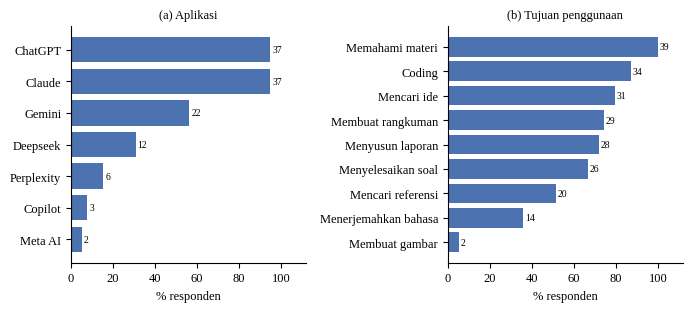

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(7, 3.2))
for a, pre, judul in [(ax[0], "app", "(a) Aplikasi"), (ax[1], "tujuan", "(b) Tujuan penggunaan")]:
    p = df[kol(pre)].mean().sort_values()
    a.barh([x.split(":")[1] for x in p.index], 100 * p.values, color="#4C72B0")
    for i, v in enumerate(p.values):
        a.text(100 * v + 1, i, f"{int(round(v * len(df)))}", va="center", fontsize=7)
    a.set_xlim(0, 112); a.set_xlabel("% responden"); a.set_title(judul, fontsize=9)
    a.spines[["top", "right"]].set_visible(False)
fig.tight_layout(); fig.savefig(OUT / "pratinjau_gambar3_aplikasi_tujuan.png"); plt.show()

### Pratinjau Gambar 5 dan 6 - Distribusi jawaban per butir

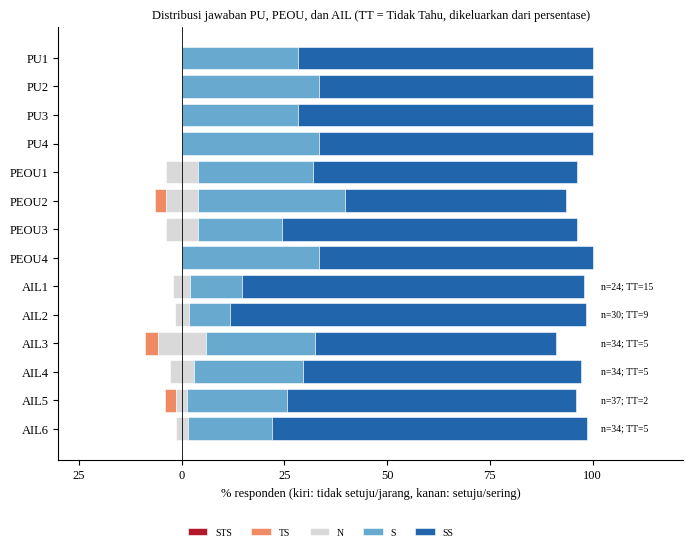

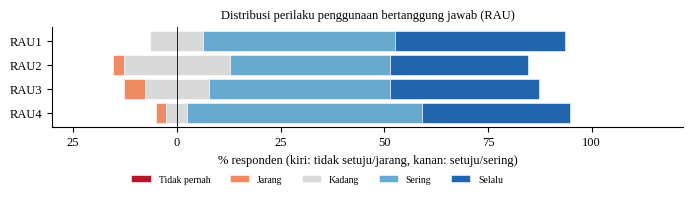

In [10]:
WARNA = ["#B2182B", "#EF8A62", "#D9D9D9", "#67A9CF", "#2166AC"]
def diverging(items, label_skala, nama_file, judul):
    fig, ax = plt.subplots(figsize=(7, 0.32 * len(items) + 1.1))
    for i, k in enumerate(items[::-1]):
        s = df[k].dropna(); n = len(s)
        p = [100 * (s == v).mean() for v in range(1, 6)]
        kiri = -(p[0] + p[1] + p[2] / 2)
        for v in range(5):
            ax.barh(i, p[v], left=kiri, color=WARNA[v], edgecolor="white", linewidth=.4,
                    label=label_skala[v] if i == 0 else None)
            kiri += p[v]
        if k in AIL:
            ax.text(102, i, f"n={n}; TT={int(tt_per_butir[k])}", va="center", fontsize=7)
    ax.set_yticks(range(len(items))); ax.set_yticklabels(items[::-1])
    ax.axvline(0, color="black", linewidth=.6); ax.set_xlim(-30, 122)
    tk = [-25, 0, 25, 50, 75, 100]; ax.set_xticks(tk); ax.set_xticklabels([abs(t) for t in tk])
    ax.set_xlabel("% responden (kiri: tidak setuju/jarang, kanan: setuju/sering)")
    ax.set_title(judul, fontsize=9); ax.spines[["top", "right"]].set_visible(False)
    ax.legend(ncol=5, fontsize=7, loc="upper center",
              bbox_to_anchor=(.42, -.55 / (0.32 * len(items) + 0.2) - .02), frameon=False)
    fig.tight_layout(); fig.savefig(OUT / nama_file); plt.show()

diverging(PU + PEOU + AIL, ["STS", "TS", "N", "S", "SS"], "pratinjau_gambar5_likert_pu_peou_ail.png",
          "Distribusi jawaban PU, PEOU, dan AIL (TT = Tidak Tahu, dikeluarkan dari persentase)")
diverging(RAU, ["Tidak pernah", "Jarang", "Kadang", "Sering", "Selalu"], "pratinjau_gambar6_rau.png",
          "Distribusi perilaku penggunaan bertanggung jawab (RAU)")

## 6. Analisis pola
### Pratinjau Gambar 4 - Ko-okurensi tujuan (indeks Jaccard)
Jaccard(A,B) = jumlah responden yang memilih A **dan** B ÷ jumlah yang memilih A **atau** B. Nilai 1 = selalu dipilih bersama.

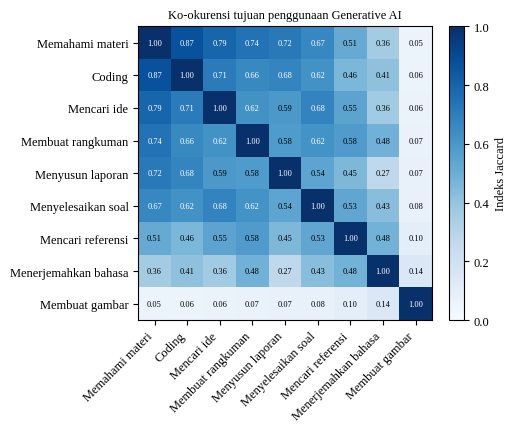

In [11]:
T = df[kol("tujuan")].rename(columns=lambda x: x.split(":")[1])
T = T.loc[:, T.sum() > 0]
nama = list(T.columns)
J = pd.DataFrame(index=nama, columns=nama, dtype=float)
for a_, b_ in itertools.product(nama, nama):
    inter = (T[a_] & T[b_]).sum(); union = (T[a_] | T[b_]).sum()
    J.loc[a_, b_] = inter / union if union else np.nan
J.round(3).to_csv(OUT / "lampiran_jaccard_tujuan.csv")

fig, ax = plt.subplots(figsize=(5.2, 4.4))
im = ax.imshow(J.values.astype(float), cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(len(nama))); ax.set_xticklabels(nama, rotation=45, ha="right")
ax.set_yticks(range(len(nama))); ax.set_yticklabels(nama)
for i in range(len(nama)):
    for j in range(len(nama)):
        v = J.values[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=6, color="white" if v > .6 else "black")
fig.colorbar(im, ax=ax, fraction=.046, label="Indeks Jaccard")
ax.set_title("Ko-okurensi tujuan penggunaan Generative AI", fontsize=9)
fig.tight_layout(); fig.savefig(OUT / "pratinjau_gambar4_jaccard_tujuan.png"); plt.show()

### Tabel 3 — Aturan asosiasi
Contoh aturan: *Membuat rangkuman + Menyelesaikan soal → Mencari referensi*.
- **support** = proporsi responden yang memiliki seluruh item dalam aturan.
- **confidence** = dari yang memiliki sisi kiri, berapa persen juga memiliki sisi kanan.
- **lift** > 1 = kombinasi muncul lebih sering daripada kebetulan.

Item yang dipilih > 90% responden dikeluarkan karena tidak membedakan antarresponden. Aturan berantecedent 2 item dibuang jika versi 1 item-nya sudah sama kuat (redundan).

In [12]:
I = pd.concat([T, df[kol("app")].rename(columns=lambda x: "App " + x.split(":")[1])], axis=1).astype(bool)
MAX_PREVALENSI = 0.90
universal = list(I.columns[I.mean() > MAX_PREVALENSI])
I = I.loc[:, (I.sum() > 0) & (I.mean() <= MAX_PREVALENSI)]
MIN_SUPPORT, MIN_CONF = 0.30, 0.70
print("Item universal dikeluarkan:", universal)

aturan = []
for k in (1, 2):
    for ant in itertools.combinations(I.columns, k):
        m_ant = I[list(ant)].all(axis=1)
        if m_ant.mean() < MIN_SUPPORT: continue
        for kons in I.columns:
            if kons in ant: continue
            sup = (m_ant & I[kons]).mean()
            if sup < MIN_SUPPORT: continue
            conf = sup / m_ant.mean(); lift = conf / I[kons].mean()
            if conf >= MIN_CONF:
                aturan.append([" + ".join(ant), kons, round(sup, 3), round(conf, 3), round(lift, 3),
                               int((m_ant & I[kons]).sum())])
aturan = pd.DataFrame(aturan, columns=["antecedent", "consequent", "support", "confidence", "lift", "n"])
aturan = aturan[aturan.lift > 1].copy()
conf1 = {(r.antecedent, r.consequent): r.confidence for r in aturan.itertuples() if " + " not in r.antecedent}
def redundan(r):
    if " + " not in r.antecedent: return False
    return any(conf1.get((a, r.consequent), 0) >= r.confidence for a in r.antecedent.split(" + "))
aturan = aturan[~aturan.apply(redundan, axis=1)].sort_values(["lift", "support"], ascending=False)
aturan.to_csv(OUT / "lampiran_aturan_asosiasi_semua.csv", index=False)
aturan.head(10).to_csv(OUT / "tabel3_aturan_asosiasi_top10.csv", index=False)
print("Jumlah aturan:", len(aturan))
aturan.head(10)

Item universal dikeluarkan: ['Memahami materi', 'App ChatGPT', 'App Claude']
Jumlah aturan: 69


,antecedent,consequent,support,confidence,lift,n
77,Membuat rangkuman + Menyelesaikan soal,Mencari referensi,0.410,0.762,1.486,16
92,Menyusun laporan + Menyelesaikan soal,Mencari referensi,0.359,0.737,1.437,14
96,Menyusun laporan + Mencari referensi,Menyelesaikan soal,0.359,0.933,1.400,14
103,Menyelesaikan soal + Mencari referensi,Membuat rangkuman,0.410,1.000,1.345,16
25,Menerjemahkan bahasa,Membuat rangkuman,0.359,1.000,1.345,14
81,Membuat rangkuman + Mencari referensi,Menyelesaikan soal,0.410,0.889,1.333,16
26,Menerjemahkan bahasa,Menyelesaikan soal,0.308,0.857,1.286,12
43,Coding + Mencari referensi,Membuat rangkuman,0.410,0.941,1.266,16
95,Menyusun laporan + Mencari referensi,Membuat rangkuman,0.359,0.933,1.255,14
65,Mencari ide + Mencari referensi,Menyelesaikan soal,0.385,0.833,1.250,15


### Lampiran — Frequent itemset tujuan penggunaan
Kombinasi tujuan yang dipilih bersama oleh ≥ 50% responden (di sini item universal tetap disertakan, karena itemset menggambarkan "paket" penggunaan). Juga dihitung berapa banyak kombinasi tujuan yang berbeda di antara responden.

In [17]:
TB = T.astype(bool)
itemset = []
for k in range(2, len(TB.columns) + 1):
    ada = False
    for s in itertools.combinations(TB.columns, k):
        sup = TB[list(s)].all(axis=1).mean()
        if sup >= 0.50:
            itemset.append([k, " + ".join(s), round(sup, 3), int(round(sup * len(TB)))]); ada = True
    if not ada: break
itemset = pd.DataFrame(itemset, columns=["ukuran", "itemset", "support", "n"]).sort_values(["ukuran", "support"], ascending=[True, False])
itemset.to_csv(OUT / "lampiran_frequent_itemset_tujuan.csv", index=False)

profil_tujuan = TB.apply(lambda r: " + ".join(k for k, v in r.items() if v), axis=1).value_counts()
print(f"Kombinasi tujuan berbeda: {len(profil_tujuan)} dari {len(TB)} responden; "
      f"{int((profil_tujuan == 1).sum())} kombinasi hanya dimiliki satu orang; kombinasi terbanyak dimiliki {profil_tujuan.iloc[0]} orang")
itemset.groupby("ukuran").head(3)

Kombinasi tujuan berbeda: 24 dari 39 responden; 14 kombinasi hanya dimiliki satu orang; kombinasi terbanyak dimiliki 6 orang


,ukuran,itemset,support,n
0,2,Memahami materi + Coding,0.872,34
1,2,Memahami materi + Mencari ide,0.795,31
2,2,Memahami materi + Membuat rangkuman,0.744,29
15,3,Memahami materi + Coding + Mencari ide,0.692,27
16,3,Memahami materi + Coding + Membuat rangkuman,0.641,25
17,3,Memahami materi + Coding + Menyusun laporan,0.641,25
27,4,Memahami materi + Coding + Mencari ide + Membu...,0.513,20
28,4,Memahami materi + Coding + Mencari ide + Menyu...,0.513,20
29,4,Memahami materi + Coding + Mencari ide + Menye...,0.513,20


### Tabel 4 Aturan aplikasi ke tujuan
Untuk aplikasi yang dipakai ≥ 5 responden (selain ChatGPT dan Claude yang universal): tujuan apa yang lebih sering menyertai pengguna aplikasi tersebut? Hanya aturan dengan lift ≥ 1,2 yang ditampilkan.

In [19]:
aplikasi_cols = [k for k in I.columns if k.startswith("App ") and I[k].sum() >= 5]
tujuan_cols = [k for k in I.columns if not k.startswith("App ")]
aturan_app = []
for a in aplikasi_cols:
    for t in tujuan_cols:
        n_ab = int((I[a] & I[t]).sum()); conf = n_ab / I[a].sum(); lift = conf / I[t].mean()
        if lift >= 1.2 and n_ab >= 4:
            aturan_app.append([a, t, int(I[a].sum()), n_ab, round(n_ab / len(I), 3), round(conf, 3), round(lift, 3)])
aturan_app = pd.DataFrame(aturan_app, columns=["aplikasi", "tujuan", "n_pengguna_aplikasi", "n", "support",
                                               "confidence", "lift"]).sort_values("lift", ascending=False)
aturan_app.to_csv(OUT / "tabel4_aturan_aplikasi_tujuan.csv", index=False)
aturan_app

,aplikasi,tujuan,n_pengguna_aplikasi,n,support,confidence,lift
5,App Perplexity,Menyelesaikan soal,6,6,0.154,1.000,1.500
3,App Deepseek,Mencari referensi,12,9,0.231,0.750,1.463
1,App Deepseek,Menyusun laporan,12,11,0.282,0.917,1.277
0,App Gemini,Menerjemahkan bahasa,22,10,0.256,0.455,1.266
4,App Perplexity,Mencari ide,6,6,0.154,1.000,1.258
2,App Deepseek,Menyelesaikan soal,12,10,0.256,0.833,1.250


### Lampiran - ARM dengan atribut literasi dan verifikasi
Apakah celah literasi ("Tidak Tahu" pada AIL1/AIL2) atau verifikasi lemah (RAU2 ≤ 3) terkonsentrasi pada pola penggunaan tertentu?
Atribut tersebut dijadikan *consequent*. Antecedent = 1–2 item tujuan/aplikasi/multi-aplikasi.
Ambang: n ≥ 4 responden, confidence ≥ 0,50, lift ≥ 1,30.

In [20]:
Ia = I.copy()
Ia["Multi-aplikasi (>=3)"] = (df["jumlah_aplikasi"] >= 3).values
target = {"TT cara kerja AI (AIL1)": (raw[c[17]] == TT).values,
          "TT keterbatasan AI (AIL2)": (raw[c[18]] == TT).values,
          "Verifikasi jarang/kadang (RAU2<=3)": (df["RAU2"] <= 3).values,
          "Verifikasi selalu (RAU2=5)": (df["RAU2"] == 5).values}
aturan_atribut = []
for nama_t, y in target.items():
    y = pd.Series(y, index=Ia.index)
    for k in (1, 2):
        for ant in itertools.combinations(Ia.columns, k):
            m = Ia[list(ant)].all(axis=1); n_ab = int((m & y).sum())
            if m.sum() < 4 or n_ab < 4: continue
            conf = n_ab / m.sum(); lift = conf / y.mean()
            if conf >= 0.50 and lift >= 1.30:
                aturan_atribut.append([" + ".join(ant), nama_t, n_ab, round(n_ab / len(Ia), 3), round(conf, 3), round(lift, 3)])
aturan_atribut = pd.DataFrame(aturan_atribut, columns=["antecedent", "consequent", "n", "support", "confidence", "lift"])
aturan_atribut.to_csv(OUT / "lampiran_aturan_literasi_verifikasi.csv", index=False)
print("Prevalensi atribut:", {k: round(float(np.mean(v)), 3) for k, v in target.items()})
print("Jumlah aturan yang lolos ambang:", len(aturan_atribut))
aturan_atribut

Prevalensi atribut: {'TT cara kerja AI (AIL1)': 0.385, 'TT keterbatasan AI (AIL2)': 0.231, 'Verifikasi jarang/kadang (RAU2<=3)': 0.282, 'Verifikasi selalu (RAU2=5)': 0.333}
Jumlah aturan yang lolos ambang: 1


,antecedent,consequent,n,support,confidence,lift
0,Menyelesaikan soal + Menerjemahkan bahasa,Verifikasi jarang/kadang (RAU2<=3),6,0.154,0.5,1.773


## 7. Evaluasi instrumen dan analisis asosiasi
### Tabel 5 — Cronbach's Alpha dengan CI bootstrap 95%
Alpha hanya pemeriksaan awal konsistensi internal, **bukan bukti tunggal validitas**. Untuk AIL, hanya responden yang mengisi keenam butir tanpa "Tidak Tahu" yang ikut dihitung.

In [16]:
def alpha(X):
    X = X.dropna(); k = X.shape[1]
    return k / (k - 1) * (1 - X.var(ddof=1).sum() / X.sum(axis=1).var(ddof=1))
def boot(fn, data):
    n = len(data); v = []
    for _ in range(B):
        r = fn(data.iloc[rng.integers(0, n, n)])
        if np.isfinite(r): v.append(r)
    return np.percentile(v, [2.5, 97.5])

rel = []
for nama_k, items in {"PU": PU, "PEOU": PEOU, "AIL": AIL, "RAU": RAU}.items():
    X = df[items].dropna(); lo, hi = boot(alpha, X)
    rel.append([nama_k, len(items), len(X), alpha(X), lo, hi])
rel = pd.DataFrame(rel, columns=["konstruk", "butir", "n_lengkap", "alpha", "CI_low", "CI_high"]).round(3)
rel.to_csv(OUT / "tabel5_reliabilitas.csv", index=False)
rel

,konstruk,butir,n_lengkap,alpha,CI_low,CI_high
0,PU,4,39,0.392,-0.169,0.656
1,PEOU,4,39,0.680,0.265,0.824
2,AIL,6,16,0.862,0.356,0.948
3,RAU,4,39,0.831,0.727,0.895


### Lampiran - Korelasi Spearman pelengkap (E1–E4)
Spearman (ρ) dengan CI bootstrap 95%, Kendall tau-b sebagai pembanding (lebih tahan terhadap nilai kembar), dan koreksi Benjamini–Hochberg (q) untuk uji berganda.

Dengan n ≈ 39, korelasi terkecil yang dapat terdeteksi (daya 80%, α = 0,05) sekitar 0,44. Hasil tidak signifikan ditulis sebagai **"tidak terdeteksi asosiasi"**, bukan "tidak ada hubungan".

In [21]:
def bh(p):
    p = np.asarray(p, float); m = len(p); o = np.argsort(p)
    q = p[o] * m / np.arange(1, m + 1); q = np.minimum.accumulate(q[::-1])[::-1]
    out = np.empty(m); out[o] = np.minimum(q, 1); return out

HIP = [("E1", "PU", "keluasan_tujuan"), ("E2", "PEOU", "keluasan_tujuan"),
       ("E3", "AIL", "RAU"), ("E4", "AIL", "keluasan_tujuan")]
aso = []
for kode, x, y in HIP:
    d = df[[x, y]].dropna()
    rho, p = spearmanr(d[x], d[y]); lo, hi = boot(lambda s: spearmanr(s[x], s[y])[0], d)
    tau = kendalltau(d[x], d[y])
    aso.append([kode, x, y, len(d), rho, lo, hi, p, tau.statistic, tau.pvalue])
aso = pd.DataFrame(aso, columns=["kode", "X", "Y", "n", "rho", "rho_CI_low", "rho_CI_high", "p_spearman",
                                 "tau_b", "p_kendall"])
aso["q_BH"] = bh(aso.p_spearman)
aso.round(3).to_csv(OUT / "lampiran_korelasi_spearman.csv", index=False)
aso.round(3)

,kode,X,Y,n,rho,rho_CI_low,rho_CI_high,p_spearman,tau_b,p_kendall,q_BH
0,E1,PU,keluasan_tujuan,39,0.096,-0.200,0.380,0.562,0.076,0.561,0.853
1,E2,PEOU,keluasan_tujuan,39,-0.031,-0.342,0.285,0.853,-0.013,0.919,0.853
2,E3,AIL,RAU,36,-0.133,-0.457,0.240,0.439,-0.084,0.518,0.853
3,E4,AIL,keluasan_tujuan,36,-0.044,-0.414,0.324,0.799,-0.056,0.675,0.853


### Proksi bias nonrespons - responden awal vs akhir
Responden yang mengisi belakangan sering lebih mirip non-responden. Uji Mann–Whitney; *rank_biserial* > 0 berarti kelompok awal cenderung lebih tinggi.

In [22]:
akhir = df.urutan > len(df) / 2
nr = []
for v in ["PU", "PEOU", "AIL", "RAU", "keluasan_tujuan", "jumlah_aplikasi"]:
    a_, b_ = df.loc[~akhir, v].dropna(), df.loc[akhir, v].dropna()
    u, p = mannwhitneyu(a_, b_, alternative="two-sided")
    nr.append([v, len(a_), a_.median(), len(b_), b_.median(), u, p, 2 * u / (len(a_) * len(b_)) - 1])
nr = pd.DataFrame(nr, columns=["variabel", "n_awal", "median_awal", "n_akhir", "median_akhir", "U", "p",
                               "rank_biserial"]).round(3)
nr.to_csv(OUT / "lampiran_awal_vs_akhir.csv", index=False)
nr

,variabel,n_awal,median_awal,n_akhir,median_akhir,U,p,rank_biserial
0,PU,19,4.75,20,4.75,174.5,0.659,-0.082
1,PEOU,19,4.75,20,4.75,150.5,0.259,-0.208
2,AIL,17,5.00,19,4.80,159.0,0.947,-0.015
3,RAU,19,4.50,20,3.75,291.0,0.004,0.532
4,keluasan_tujuan,19,5.00,20,6.00,215.0,0.485,0.132
5,jumlah_aplikasi,19,3.00,20,2.50,253.5,0.060,0.334
